In [1]:
import os
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
os.environ["PYVISTA_OFF_SCREEN"] = "True"
os.environ["PYVISTA_USE_WGL"] = "True"
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '1' #Select the GPU Card
print('Process id: ',os.getpid())
# !pip install trimesh


import os, glob, csv, h5py, pickle, struct, cv2, imageio, timeit, sys, shutil
import numpy as np
#print(np.__version__)
import pandas as pd
import math as math
import scipy.io as sio
import scipy.stats as stats
import scipy.linalg as linalg
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import ipywidgets as widgets
import time as time
import trimesh
import open3d as o3d
import pyvista as pv
import pydicom
from pydicom.filereader import dcmread
from pydicom.pixel_data_handlers.util import apply_modality_lut


from os import environ, listdir
from os.path import dirname, abspath
from sys import argv
from numpy import zeros, newaxis
from random import randint, choice, shuffle, sample
from itertools import product
from scipy import signal
from scipy.io import loadmat
from scipy import ndimage, misc
from scipy.ndimage.interpolation import rotate, zoom
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.utils import class_weight
from cv2 import imread, imwrite
from PIL import Image, ImageOps
from skimage.exposure import rescale_intensity, adjust_gamma
from scipy.ndimage import map_coordinates, gaussian_filter
from skimage.filters import threshold_otsu
from skimage.measure import label, regionprops
from ipywidgets import interact, interactive, fixed, interact_manual
# from construct import PaddedString, Int16un, Struct, Int32un, Int8un, Array
from pathlib import Path


import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPUs detected:", tf.config.list_physical_devices('GPU'))
import tensorflow.keras
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Layer

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, load_model, Model
from tensorflow.keras.layers import GlobalMaxPooling2D, GlobalAveragePooling2D,\
 MaxPooling2D, ZeroPadding2D, UpSampling2D, concatenate, Average, add, Reshape, Permute, Conv2D,\
 Conv2DTranspose, SeparableConv2D, ELU, BatchNormalization, AveragePooling2D, Cropping2D, \
 Flatten, Dense, Dropout, Activation, SpatialDropout2D
from tensorflow.keras.optimizers import RMSprop, SGD, Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping, LearningRateScheduler, Callback
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model, to_categorical, Sequence

from scipy.ndimage import zoom

from skimage import feature

Process id:  24061
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


/tmp/ipykernel_24061/1015792875.py:41: DeprecationWarning: scipy.misc is deprecated and will be removed in 2.0.0
  from scipy import ndimage, misc
/tmp/ipykernel_24061/1015792875.py:42: DeprecationWarning: Please import `rotate` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.interpolation import rotate, zoom
/tmp/ipykernel_24061/1015792875.py:42: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.interpolation import rotate, zoom
2026-07-29 10:48:58.733137: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-29 10:48:59.048909:

TensorFlow version: 2.18.0
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def DicomReader(dicom_folder_path):
    # --- Collect DICOM files ---
    dicom_files = [
        os.path.join(dicom_folder_path, f)
        for f in os.listdir(dicom_folder_path)
        if f.endswith(".dcm")
    ]
    if len(dicom_files) == 0:
        raise ValueError("No DICOM files found in folder.")

    # --- Pick the largest (likely multi-frame) DICOM ---
    dicom_files.sort(key=os.path.getsize, reverse=True)
    selected_file = dicom_files[0]
    if len(dicom_files) > 1:
        print(f"Multiple DICOMs found. Using the largest file: {os.path.basename(selected_file)}")

    dcm = dcmread(selected_file)

    # --- Get OCT volume ---
    oct_volume = apply_modality_lut(dcm.pixel_array, dcm)  # Shape: (frames, H, W)
    if oct_volume.ndim == 3:
        oct_volume = np.transpose(oct_volume, (1, 2, 0))  # (H, W, slices)
    elif oct_volume.ndim == 2:
        oct_volume = np.expand_dims(oct_volume, axis=-1)  # Single slice

    # --- Extract voxel spacing ---
    dx = float(getattr(dcm, "PixelSpacing", [1, 1])[0])
    dy = float(getattr(dcm, "PixelSpacing", [1, 1])[1])
    dz = float(getattr(dcm, "SpacingBetweenSlices", getattr(dcm, "SliceThickness", 1.0)))

    # --- Prepare output dict ---
    volData = {
        'OCTFrames': oct_volume,
        'voxelDimensions': [dx, dy, dz],
        'NumBScans': oct_volume.shape[2],
        'SizeY': oct_volume.shape[0],
        'SizeX': oct_volume.shape[1],
        'SizeXSlo': 0,
        'SizeYSlo': 0,
        'ScaleXSlo': 0,
        'ScaleYSlo': 0,
        'SLO': None,
        'BScanLines': np.zeros((oct_volume.shape[2], 2, 2)),
        'SegArray': np.zeros((oct_volume.shape[1], 17, oct_volume.shape[2])),
        'ScanPosition': getattr(dcm, 'PatientPosition', 'Unknown')
    }

    return volData
    
def process_label(label_file):
    """
    This fucntion takes label files with layers marked from 1 to 8, not 0 to 7
    """
    colors = np.zeros((9,3),dtype=np.uint8)
    
    # #### colors for each label edit accordingly
    # colors[0] = [0, 0, 0]
    # colors[1] = [255,0,0]
    # colors[2] = [0,255,0]
    # colors[3] = [0,0,255]
    # colors[4] = [255,255,0]
    # colors[5] = [255,0,255]
    # colors[6] = [0, 255, 255]
    # colors[7] = [255, 153, 51]
    # #colors[8] = [255, 255, 255]
    #### Define colors for each label
    colors[0] = [255, 255, 255]  # Background (white)
    colors[1] = [255, 0, 0]      # Class 1 (Red)
    colors[2] = [0, 255, 0]      # Class 2 (Green)
    colors[3] = [0, 0, 255]      # Class 3 (Blue)
    colors[4] = [0, 255, 255]     # Class 4 (cyan)
    colors[5] = [255, 165, 0]    # Class 5 (Orange)
    colors[6] = [150, 75, 0]    # Class 6 (Brown)
    colors[7] = [238, 130, 238]  # Class 7 (Violet)
    
    H = np.shape(label_file)[0]
    W = np.shape(label_file)[1]
    
   # img = np.zeros((H,W,3),dtype=np.uint8)
    img = np.full((H, W, 3), 255, dtype=np.uint8)  # White background for solid map
    # for i,j in product(range(H),range(W)):
    #     img[i, j] = colors[label_file[i,j]]
    for i in range(1, len(colors)):  # Assuming labels from 1 to 8
        img[label_file == i] = colors[i]  # Fill segmented areas with solid color
    
    return np.asarray(img)


def GetBscansFromVolFile(volData):
  # bscan_all = interpolate_data(vol_list['OCTFrames'], (496, 384, 97), (192, 536, 361))

    bscan_all = volData['OCTFrames']

    bscan_resize = []
    for x in range(np.shape(bscan_all)[2]):
        bscan = bscan_all[:,:,x]
        bscan[bscan > 255] = 0
        bscan1 = np.asarray(bscan, dtype=np.uint8)
        bscan_resize.append(bscan1)
    
    bscan_resize = np.asarray(bscan_resize,dtype = np.uint8)
    return bscan_resize


def NormalizeImage(img):
  if (np.max(img)-np.min(img)) != 0:
    norm_img = (img-np.min(img))/(np.max(img)-np.min(img))
  else:
    norm_img = np.copy(img)

  return  norm_img
   
def GetSegmentedBscans(bscan_all_):
  bscan_resize = []
  for x in range(np.shape(bscan_all_)[0]):
    bscan1 = np.asarray(Image.fromarray(np.asarray(bscan_all_[x, :,:],dtype = np.uint8)).resize((400,200)), dtype = np.uint8)
    bscan1 = NormalizeImage(bscan1)
    bscan_resize.append(bscan1)

  bscan_resize = np.asarray(bscan_resize)
  bscan_resize_exp = np.expand_dims(bscan_resize,axis=3)
  # # print(np.shape(bscan_resize_exp))
  # class DynamicCropLayer(Layer):
  #   def __init__(self, **kwargs):
  #       super(DynamicCropLayer, self).__init__(**kwargs)

  #   def call(self, inputs):  
  #       target_shape = tf.shape(inputs[1])  
  #       input_shape = tf.shape(inputs[0])  
  #       crop_height = (input_shape[1] - target_shape[1]) // 2
  #       crop_width = (input_shape[2] - target_shape[2]) // 2
        
  #       cropped = tf.slice(
  #           inputs[0],
  #           [0, crop_height, crop_width, 0],
  #           [-1, target_shape[1], target_shape[2], -1]
  #       )
  #       return cropped  

  # load model
  modelpath = './../../../../../mnt/DATA/sda1/Suraj/New directory/Model_checkpoints/'
  model = load_model(modelpath + 'Attention_UNet_cce_pf_weight_1.h5', compile = False)
  # model = load_model(modelpath + 'Dunet_cce.h5', 
  #                  custom_objects={'DynamicCropLayer': DynamicCropLayer}, 
  #                  compile=False)
  model.load_weights(modelpath+'best_weights_Attention_UNet_cce_pf_weight_1.weights.h5')
  # model = load_model(modelpath + 'OCT_segmentation_1_unetplus_cce.h5')
  # model.load_weights(modelpath+'best_weights_OCT_segmentation_1_unetplus_cce.weights.h5')
  # print('Model loaded...')    

  # get prediction
  bscan_preds = model.predict(bscan_resize_exp)
  # print(np.shape(bscan_preds))

  # convert segmnetation back into original resolution
  bscan_preds1=[]
  for x in range(len(bscan_preds)):
    temp1 = np.array( np.argmax(bscan_preds[x],axis=2) , dtype=np.uint8)
    bscan_preds1.append(temp1)
  bscan_preds1 = np.array(bscan_preds1)
  # print(np.shape(bscan_preds1))

  return bscan_resize, bscan_preds1 


def interpolate_data(data, data_shape, target_shape):
    # Compute zoom factors for each dimension
    zoom_factors = (target_shape[0] / data_shape[0],
                  target_shape[1] / data_shape[1],
                  target_shape[2] / data_shape[2])
    interpolated_data = zoom(data, zoom_factors)
    
    print("Interpolated shape:", interpolated_data.shape)
    
    return interpolated_data


def ExtractONHLayer(bscan_segmented_, layermarker):
    layer = []
    for i in range(len(bscan_segmented_)):
        bscan = np.copy(bscan_segmented_[i])
        bscan[bscan!=layermarker] = 0
        bscan[bscan==layermarker] = 1
    
        bscan = np.asarray(bscan,dtype = np.uint8)
        # bscan = np.asarray(Image.fromarray(bscan).resize((534,192)), dtype = np.uint8)
    
        layer.append(bscan)
    
    layer = np.array(layer)
    return layer



def ZoomNumpyVolume(numpyarr):
    # Compute the zoom factors
    zoom_factors = (400 /68, 1, 1)  # Scale only along the first axis
    
    # Apply zoom
    resized_arr = zoom(numpyarr, zoom_factors, order=3)  # Cubic interpolation (order=3)

    return resized_arr




def RnflEnfaceView(rnfl_layer_,rpe_layer_, dx,dz, dy):
  rnfl_thickness=[]
  for i in range(len(rnfl_layer_)):
    img = rnfl_layer_[i]
    thick = np.sum(img,axis =0)*dz*100
    rnfl_thickness.append(thick)

  rnfl_thickness = np.array(rnfl_thickness)

  rpe_thickness=[]
  for i in range(len(rpe_layer_)):
    img = rpe_layer_[i]
    thick = np.sum(img,axis =0) #um
    rpe_thickness.append(thick)

  rpe_thickness = np.array(rpe_thickness)
  rpe_thickness[rpe_thickness !=0] =1

  rnfl_thickness_new = rnfl_thickness #*rpe_thickness

  # rnfl_thickness_new = np.asarray(Image.fromarray(np.asarray(rnfl_thickness_new,dtype = np.uint8)).resize((400,200)), dtype = np.uint8)

  return rnfl_thickness_new


def GclEnfaceView(gcl_layer_, rpe_layer_, dx, dz, dy):
    gcl_thickness = []

    # Compute GCL thickness for each slice
    for img in gcl_layer_:
        thick = np.sum(img, axis=0) * dz*100  # Sum over depth, convert mm -> µm
        gcl_thickness.append(thick)

    gcl_thickness = np.array(gcl_thickness)

    # Create RPE mask
    rpe_thickness = []
    for img in rpe_layer_:
        thick = np.sum(img, axis=0)
        rpe_thickness.append(thick)

    rpe_thickness = np.array(rpe_thickness)
    rpe_thickness[rpe_thickness != 0] = 1  # Binary mask

    # Optionally apply the RPE mask to GCL thickness
    gcl_thickness_new = gcl_thickness

    return gcl_thickness_new

def OrlEnfaceView(orl_layer_, rpe_layer_, dx, dz, dy):
    orl_thickness = []

    # Compute ORL thickness for each slice
    for img in orl_layer_:
        thick = np.sum(img, axis=0) * dz *100  # Sum over depth, convert mm -> µm
        orl_thickness.append(thick)

    orl_thickness = np.array(orl_thickness)

    # Create RPE mask
    rpe_thickness = []
    for img in rpe_layer_:
        thick = np.sum(img, axis=0)
        rpe_thickness.append(thick)

    rpe_thickness = np.array(rpe_thickness)
    rpe_thickness[rpe_thickness != 0] = 1  # Binary mask

    # Optionally apply the RPE mask
    orl_thickness_new = orl_thickness  # * rpe_thickness

    return orl_thickness_new


def RpeEnfaceView(rpe_layer_, dx, dz, dy):
    rpe_thickness = []

    # Compute RPE thickness for each slice
    for img in rpe_layer_:
        thick = np.sum(img, axis=0) *dz*100  # Sum over depth, convert mm -> µm
        rpe_thickness.append(thick)

    rpe_thickness = np.array(rpe_thickness)

    # No need for another RPE mask here — RPE layer itself is what we want
    rpe_thickness_new = rpe_thickness

    # Optional resizing step (commented out)
    # rpe_thickness_new = np.asarray(Image.fromarray(np.asarray(rpe_thickness_new, dtype=np.uint8)).resize((400, 200)), dtype=np.uint8)

    return rpe_thickness_new


In [5]:
dicom_data = dcmread('./../../../../..//mnt/DATA/sda1/Suraj/AIIMSNagpur/Final_case_group/IAS001-20260630T055445Z-3-001/IAS001/onh/DESKTOP-B2D0PPH_AIIMS Nagpur_45952.705347222225_6e310000_132/45952.705347222225_6e310000_133.dcm')

In [6]:
dicom_data

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 204
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Ophthalmic Photography 8 Bit Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.33437.10.4.3572966.13404638208.2059.4.0.0
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', '', 'RED']
(0008,0012) Instance Creation Date              DA: '20251022'
(0008,0013) Instance Creation Time              TM: '165542'
(0008,0016) SOP Class UID                       UI: Ophthalmic Photography 

In [7]:
# print(dicom_data['PixelData'])

# img = np.array(dicom_data['PixelData'])
# print((img))

In [8]:
if 'SharedFunctionalGroupsSequence' in dicom_data:
    shared_func_groups_seq = dicom_data.SharedFunctionalGroupsSequence
    if len(shared_func_groups_seq) > 0:
        # Check if Pixel Measures Sequence is inside the shared functional groups
        if 'PixelMeasuresSequence' in shared_func_groups_seq[0]:
            pixel_measures_sequence = shared_func_groups_seq[0].PixelMeasuresSequence
            if len(pixel_measures_sequence) > 0:
                pixel_spacing = pixel_measures_sequence[0].PixelSpacing
                print(f"Pixel Spacing: {pixel_spacing}")
            else:
                print("Pixel Measures Sequence is empty.")
        else:
            print("Pixel Measures Sequence not found in Shared Functional Groups Sequence.")
    else:
        print("Shared Functional Groups Sequence is empty.")
else:
    print("Shared Functional Groups Sequence not found in the DICOM file.")

Shared Functional Groups Sequence not found in the DICOM file.


In [10]:
# # Extract the pixel data (assuming it's stored as a single continuous array)
# pixel_data = dicom_data.pixel_array
# # Function to display a specific frame
# def display_frame(frame_idx):
#     plt.figure(figsize=(12, 6))
#     plt.imshow(pixel_data[frame_idx], cmap='gray')
#     plt.title(f"Frame {frame_idx + 1}")
#     plt.axis('on')
#     plt.show()

# # Create an interactive slider to navigate through frames
# interact(display_frame, frame_idx=widgets.IntSlider(min=0, max=pixel_data.shape[0]-1, step=1, value=0));

(768, 768)


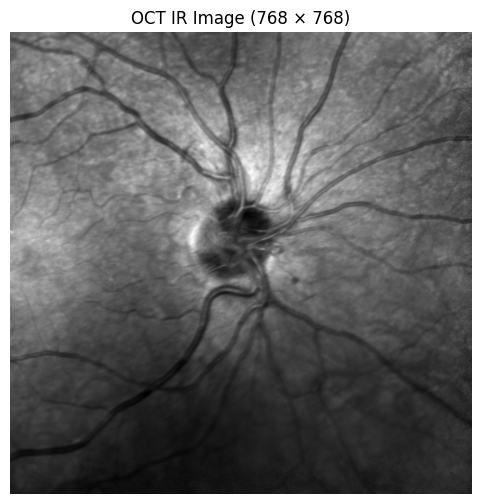

In [11]:
pixel_data = dicom_data.pixel_array  # for en-face view

# Remove singleton dimension if present
if pixel_data.ndim == 3 and pixel_data.shape[-1] == 1:
    image = pixel_data[:, :, 0]
elif pixel_data.ndim == 2:
    image = pixel_data
else:
    raise ValueError(f"Unexpected pixel_array shape: {pixel_data.shape}")

print(image.shape)  # (768, 768)

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title("OCT IR Image (768 × 768)")
plt.axis('off')
plt.show()


In [9]:
# image_norm = (image - image.min()) / (image.max() - image.min())

# plt.imsave(
#     "./../../../../../mnt/DATA/sda1/Suraj/AIIMSNagpur/Control1/en-face/N10_image_R.png",
#     image_norm,
#     cmap='gray'
# )


In [3]:
# dicom_folder_path = "./../../../../../mnt/DATA/sda1/Suraj/AIIMSNagpur/Case/Case Group/S13  854068-20260410T053521Z-3-001/S13  854068/onh/DESKTOP-B2D0PPH_AIIMS Nagpur_45952.699687499997_6e310000_78/"
# dicom_files = [os.path.join(dicom_folder_path, f) for f in os.listdir(dicom_folder_path) if f.endswith(".dcm")]

# print(f"Found {len(dicom_files)} DICOM files.")

# for f in dicom_files[:5]:  # check first 5
#     d = dcmread(f)
#     print("\nFile:", os.path.basename(f))
#     print("Rows x Cols:", d.Rows, "x", d.Columns)
#     print("SeriesDescription:", getattr(d, "SeriesDescription", "N/A"))
#     print("ImageType:", getattr(d, "ImageType", "N/A"))
#     print("InstanceNumber:", getattr(d, "InstanceNumber", "N/A"))
#     print("ImagePositionPatient:", getattr(d, "ImagePositionPatient", "N/A"))
#     print("NumberOfFrames:", getattr(d, "NumberOfFrames", "N/A"))

dicom_path = "./../../../../..//mnt/DATA/sda1/Suraj/AIIMSNagpur/Final_case_group/IAS001-20260630T055445Z-3-001/IAS001/onh/DESKTOP-B2D0PPH_AIIMS Nagpur_45952.705347222225_6e310000_132/45952.705347222225_6e310000_133.dcm"
volData = DicomReader(os.path.dirname(dicom_path))

print("OCT Volume shape:", volData['OCTFrames'].shape)
print("Voxel dimensions:", volData['voxelDimensions'])

ds = pydicom.dcmread(dicom_path)
# Most OCT DICOMs have this:
fg = ds.SharedFunctionalGroupsSequence[0]
pixel_measures = fg.PixelMeasuresSequence[0]

# Try to get lateral (x), axial (y), and depth (z) spacing
px, py = [float(x) for x in pixel_measures.PixelSpacing]  # mm per pixel
tz = float(pixel_measures.SliceThickness)  # mm per slice

print(f"Lateral spacing (X): {px} mm")
print(f"Axial spacing (Y): {py} mm")
print(f"Slice spacing (Z): {tz} mm")

spacing = (tz, py, px)  # (z, y, x)
print("Final spacing tuple (z, y, x):", spacing)



OCT Volume shape: (768, 768, 1)
Voxel dimensions: [0.011807, 0.011807, 1.0]


AttributeError: 'FileDataset' object has no attribute 'SharedFunctionalGroupsSequence'

In [13]:
if volData['SLO'] is not None:
    slodimX = volData['SizeXSlo'] * volData['ScaleXSlo']
    slodimY = volData['SizeYSlo'] * volData['ScaleYSlo']

    resize_dx = int(slodimX / volData['voxelDimensions'][0])
    resize_dy = int(slodimY / volData['voxelDimensions'][1])

    SLO_resized = np.asarray(
        Image.fromarray(volData['SLO'].astype(np.uint8)).resize((resize_dx, resize_dy)),
        dtype=np.uint8
    )

    print("SLO resized:", SLO_resized.shape)
    np.save('ONH.npy', SLO_resized)
    plt.imshow(SLO_resized, cmap='gray')
    plt.show()
else:
    print("⚠ No SLO image found in this DICOM series.")


⚠ No SLO image found in this DICOM series.


In [15]:
bscans = GetBscansFromVolFile(volData)
print(np.shape(bscans))

(73, 496, 384)


In [8]:
# # =========================
# # Create output folder
# # =========================
# save_dir = "bscan_pngs"
# os.makedirs(save_dir, exist_ok=True)

# # =========================
# # Save all B-scans
# # =========================
# for i in range(bscans.shape[0]):

#     img = bscans[i]

#     # Normalize to 0-255
#     img = img.astype(np.float32)
#     img = (img - img.min()) / (img.max() - img.min()) * 255
#     img = img.astype(np.uint8)

#     # Save PNG
#     Image.fromarray(img).save(
#         os.path.join(save_dir, f"Bscan_{i:02d}.png")
#     )

# # =========================
# # Compress folder to ZIP
# # =========================
# zip_path = shutil.make_archive(
#     "bscan_pngs",   # output zip name
#     'zip',          # format
#     save_dir        # folder to compress
# )

# print("ZIP file created:", zip_path)

In [16]:
@interact(x=(0,len(bscans)-1,1))
def h(x=0):
    f = plt.figure(figsize=(6,6))
    plt.imshow(bscans[x, :,:],cmap='gray')
    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [10]:
bscans_resize, bscans_segmented = GetSegmentedBscans(bscans)
print(np.shape(bscans_resize), np.shape(bscans_segmented))

I0000 00:00:1780571908.078338  729493 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20833 MB memory:  -> device: 0, name: NVIDIA A10, pci bus id: 0000:ca:00.0, compute capability: 8.6
I0000 00:00:1780571909.807388  730209 service.cc:148] XLA service 0x7f4788012c70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780571909.807447  730209 service.cc:156]   StreamExecutor device (0): NVIDIA A10, Compute Capability 8.6
2026-06-04 16:48:29.871072: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1780571909.988077  730209 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-04 16:48:42.803356: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 27.44GiB with freed_by_count=0. The caller indicates that this is not a fai

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 569ms/step

E0000 00:00:1780571933.505703  730205 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1780571933.669115  730205 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1780571934.146870  730205 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1780571934.348849  730205 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


3/3 ━━━━━━━━━━━━━━━━━━━━ 32s 5s/step  
(73, 200, 400) (73, 200, 400)


In [11]:
@interact(x=(0,len(bscans_segmented)-1,1))
def h(x=0):
    colorimage = process_label(bscans_segmented[x, :,:])
    
    f = plt.figure(figsize=(12,6))
    f.add_subplot(1,3,1)
    plt.imshow(bscans_resize[x, :,:],cmap='gray')
    plt.axis('off')

    f.add_subplot(1,3,2)
    plt.imshow(colorimage)
    plt.axis('off')

    f.add_subplot(1,3,3)
    plt.imshow(bscans_resize[x, :,:],cmap='gray')
    plt.imshow(colorimage, alpha = 0.25)
    plt.axis('off')

    plt.show()

interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [50]:
# dx, dy, dz = volData['voxelDimensions']  # from DICOM
dz, dy, dx = np.array(spacing)
print("dz, dy, dx:", dz,dy, dx)

dz, dy, dx: 0.059714 0.011211 0.003872


In [51]:
# dx = volData['SizeX'] * dx / 400
# dy = volData['SizeY'] * dy / 200
# dz = volData['NumBScans'] * dz / 73

bscan_zoomed = interpolate_data(bscans_segmented, (73, 200, 400), (73, 200, 400))

Interpolated shape: (73, 200, 400)


In [52]:
@interact(x=(0,len(bscan_zoomed)-1,1))
def h(x=0):
    colorimage = process_label(bscan_zoomed[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [53]:
rnfl = ExtractONHLayer(bscan_zoomed, 1)
print(np.unique(rnfl))
print(np.shape(rnfl))

[0 1]
(73, 200, 400)


In [54]:
# Function to remove small contours in a binary mask
def remove_small_contours(binary_mask, min_contour_area):
    cleaned_mask = np.zeros_like(binary_mask)
    for i in range(binary_mask.shape[0]):  # Iterate over slices
        slice_mask = (binary_mask[i] * 255).astype(np.uint8)  # Convert to uint8 for OpenCV

        # Find contours
        contours, _ = cv2.findContours(slice_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Filter and keep only large contours
        filtered_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_contour_area]

        # Draw filtered contours onto the cleaned mask
        cv2.drawContours(cleaned_mask[i], filtered_contours, -1, (1), thickness=cv2.FILLED)

    return cleaned_mask

# Example usage
min_contour_area = 1000  # Adjust based on your dataset
cleaned_rnfl = remove_small_contours(rnfl, min_contour_area)

# Print confirmation
print("Unique values after cleaning:", np.unique(cleaned_rnfl))
print("Shape of cleaned RNFL:", np.shape(cleaned_rnfl))

Unique values after cleaning: [0 1]
Shape of cleaned RNFL: (73, 200, 400)


In [55]:
@interact(x=(0,len(cleaned_rnfl)-1,1))
def h(x=0):
    colorimage = process_label(cleaned_rnfl[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [56]:
rnfl_zoomed = ZoomNumpyVolume(cleaned_rnfl)
print(np.unique(rnfl_zoomed))
print(np.shape(rnfl_zoomed))


@interact(x=(0,len(rnfl_zoomed)-1,1))
def h(x=0):
    colorimage = process_label(rnfl_zoomed[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

[0 1]
(429, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=428), Output()), _dom_classes=('widget-interact'…

In [57]:
np.save('rnfl_zoomed.npy',rnfl_zoomed)

In [58]:
rpe = ExtractONHLayer(bscan_zoomed, 4)
print(np.unique(rpe))
print(np.shape(rpe))

@interact(x=(0,len(rpe)-1,1))
def h(x=0):
    colorimage = process_label(rpe[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

[0 1]
(73, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [59]:
GCL = ExtractONHLayer(bscan_zoomed, 2)
print(np.unique(GCL))
print(np.shape(GCL))

@interact(x=(0,len(GCL)-1,1))
def h(x=0):
    colorimage = process_label(GCL[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')  # Remove axes

[0 1]
(73, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [60]:
GCL_zoomed = ZoomNumpyVolume(GCL)
print(np.unique(GCL_zoomed))
print(np.shape(GCL_zoomed))


@interact(x=(0,len(GCL_zoomed)-1,1))
def h(x=0):
    colorimage = process_label(GCL_zoomed[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

[0 1]
(429, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=428), Output()), _dom_classes=('widget-interact'…

In [61]:
np.save('GCL_zoomed.npy',GCL_zoomed)

In [62]:
ORL = ExtractONHLayer(bscan_zoomed, 3)
print(np.unique(ORL))
print(np.shape(ORL))

@interact(x=(0,len(ORL)-1,1))
def h(x=0):
    colorimage = process_label(ORL[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')  # Remove axes

[0 1]
(73, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [63]:
ORL_zoomed = ZoomNumpyVolume(ORL)
print(np.unique(ORL_zoomed))
print(np.shape(ORL_zoomed))


@interact(x=(0,len(ORL_zoomed)-1,1))
def h(x=0):
    colorimage = process_label(ORL_zoomed[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

[0 1]
(429, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=428), Output()), _dom_classes=('widget-interact'…

In [64]:
np.save('ORL_zoomed.npy',ORL_zoomed)

In [65]:
rpe_zoomed = ZoomNumpyVolume(rpe)
print(np.unique(rpe_zoomed))
print(np.shape(rpe_zoomed))


@interact(x=(0,len(rpe_zoomed)-1,1))
def h(x=0):
    colorimage = process_label(rpe_zoomed[x, :,:])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)
    plt.axis('off')

[0 1]
(429, 200, 400)


interactive(children=(IntSlider(value=0, description='x', max=428), Output()), _dom_classes=('widget-interact'…

RNFL shape: (429, 400)
GCL shape: (429, 400)
ORL shape: (429, 400)
RPE shape: (429, 400)


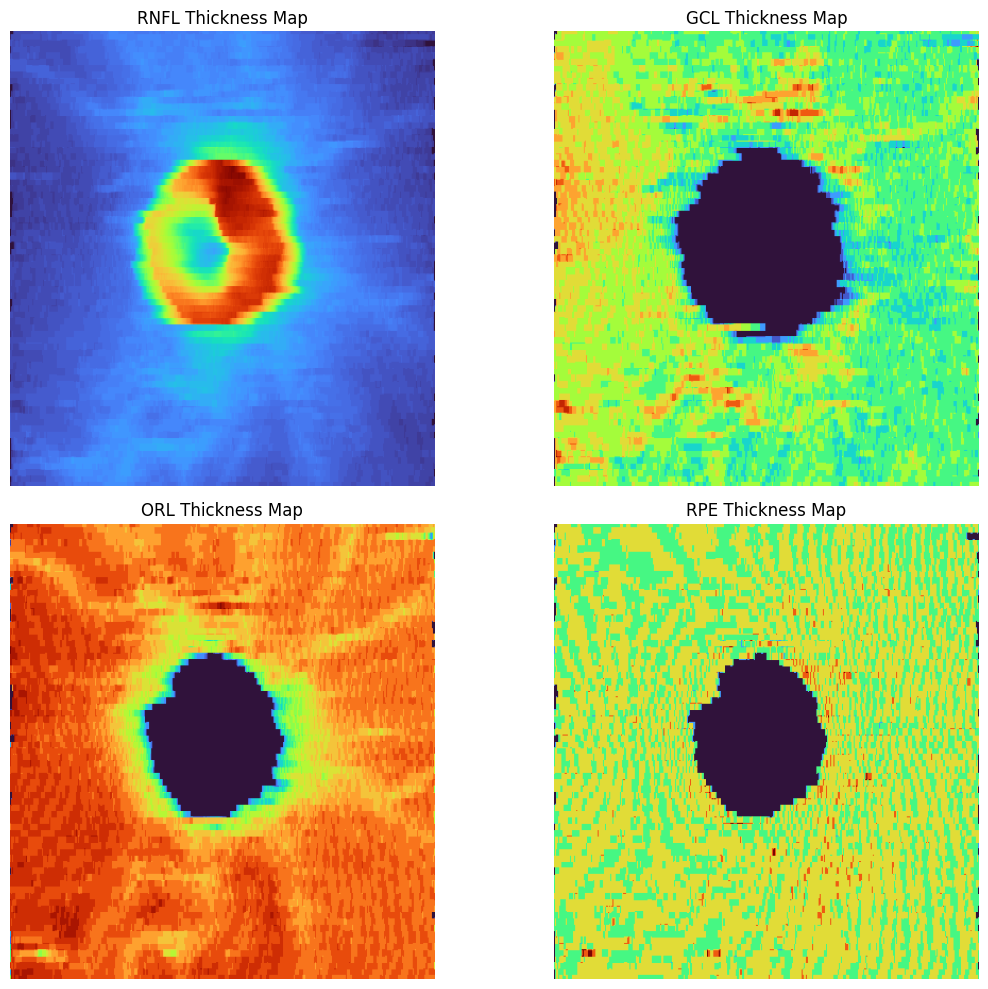

In [66]:
# dx, dy, dz = 0.01, 0.01, 0.003

# Thickness map calculation
rnfl_thickness_map = RnflEnfaceView(rnfl_zoomed, rpe_zoomed, dx, dz, dy)
GCL_thickness_map = GclEnfaceView(GCL_zoomed, rpe_zoomed, dx, dz, dy)
ORL_thickness_map = OrlEnfaceView(ORL_zoomed, rpe_zoomed, dx, dz, dy)
rpe_thickness_map = RpeEnfaceView(rpe_zoomed, dx, dz, dy)

# Saving
np.save('rnfl_thickness_map.npy', rnfl_thickness_map)
np.save('GCL_thickness_map.npy', GCL_thickness_map)
np.save('ORL_thickness_map.npy', ORL_thickness_map)
np.save('rpe_thickness_map.npy', rpe_thickness_map)

# Printing shapes
print("RNFL shape:", np.shape(rnfl_thickness_map))
print("GCL shape:", np.shape(GCL_thickness_map))
print("ORL shape:", np.shape(ORL_thickness_map))
print("RPE shape:", np.shape(rpe_thickness_map))

# Plotting - Different maps separately
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# RNFL
axs[0, 0].imshow(rnfl_thickness_map, cmap='turbo')
axs[0, 0].set_title('RNFL Thickness Map')
axs[0, 0].axis('off')

# GCL
axs[0, 1].imshow(GCL_thickness_map, cmap='turbo')
axs[0, 1].set_title('GCL Thickness Map')
axs[0, 1].axis('off')

# ORL
axs[1, 0].imshow(ORL_thickness_map, cmap='turbo')
axs[1, 0].set_title('ORL Thickness Map')
axs[1, 0].axis('off')

# RPE
axs[1, 1].imshow(rpe_thickness_map, cmap='turbo')
axs[1, 1].set_title('RPE Thickness Map')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

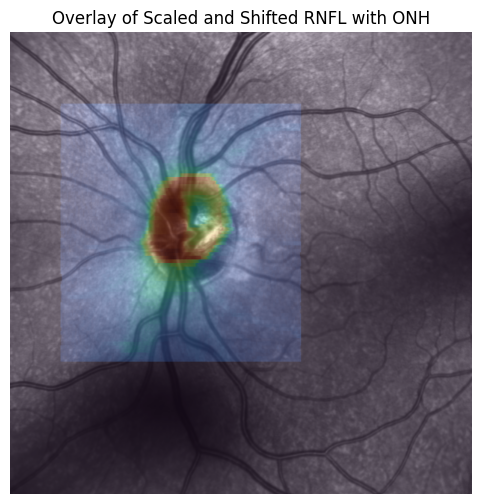

In [31]:
# Load your arrays
onh_img = np.load("ONH_AIIMS.npy")
rnfl_map = np.load("rnfl_thickness_map.npy")

# Parameters you can tweak
scale_factor = 1  # scaling factor to squeeze RNFL map
tx = -100             # translation in x (positive = right, negative = left)
ty = -50            # translation in y (positive = down, negative = up)
alpha = 0.3       # blending factor

# Step 1: Resize (scale) RNFL map
new_size = (int(rnfl_map.shape[1] * scale_factor), int(rnfl_map.shape[0] * scale_factor))
rnfl_scaled = cv2.resize(rnfl_map, new_size, interpolation=cv2.INTER_LINEAR)

# Step 2: Pad the scaled RNFL map to match ONH size
pad_x = (onh_img.shape[1] - rnfl_scaled.shape[1]) // 2
pad_y = (onh_img.shape[0] - rnfl_scaled.shape[0]) // 2

rnfl_padded = cv2.copyMakeBorder(
    rnfl_scaled, pad_y, onh_img.shape[0] - rnfl_scaled.shape[0] - pad_y,
    pad_x, onh_img.shape[1] - rnfl_scaled.shape[1] - pad_x,
    borderType=cv2.BORDER_CONSTANT, value=0
)

# Step 3: Translate the RNFL map
M = np.float32([[1, 0, tx], [0, 1, ty]])
rnfl_translated = cv2.warpAffine(rnfl_padded, M, (onh_img.shape[1], onh_img.shape[0]))

# Step 4: Apply colormap to RNFL map
rnfl_colormap = cv2.applyColorMap(
    cv2.normalize(rnfl_translated, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),
    cv2.COLORMAP_TURBO
)

# Step 5: Prepare ONH image
if len(onh_img.shape) == 2:  # if grayscale
    onh_bgr = cv2.cvtColor(onh_img, cv2.COLOR_GRAY2BGR)
else:
    onh_bgr = onh_img  # already 3-channel

# Step 6: Blend the images
overlay = cv2.addWeighted(onh_bgr, 1 - alpha, rnfl_colormap, alpha, 0)

# Step 7: Display
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Overlay of Scaled and Shifted RNFL with ONH")
plt.show()

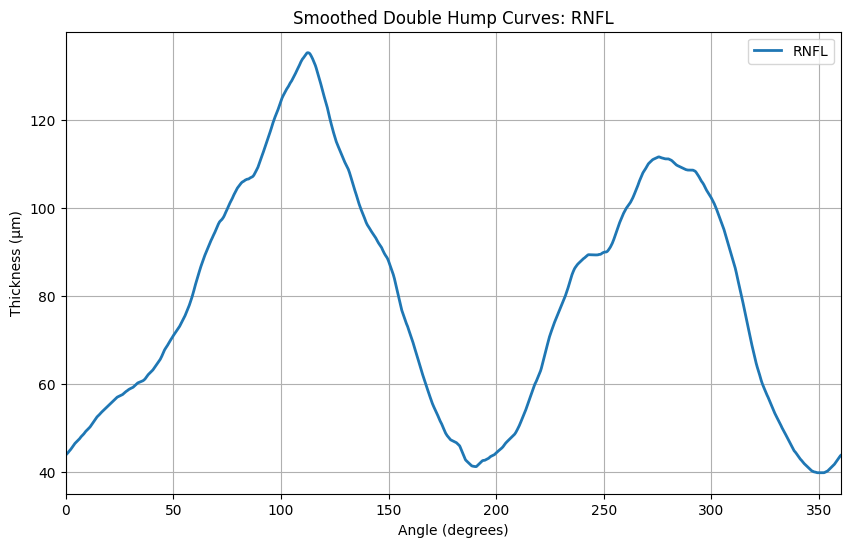

In [32]:
# Load the thickness maps
rnfl_map = np.load('rnfl_thickness_map.npy')
gcl_map = np.load('GCL_thickness_map.npy')
orl_map = np.load('ORL_thickness_map.npy')
rpe_map = np.load('rpe_thickness_map.npy')

# 1. Define center of ONH (manually or estimated)
cx, cy = rnfl_map.shape[1] // 2, rnfl_map.shape[0] // 2  # Center
r = 150  # radius in pixels (adjust based on your ONH size)

def smooth_curve_moving_average_circular(curve, window_size=5):
    """
    Smooth a 1D curve using moving average with circular padding.
    
    Args:
        curve (np.ndarray): Input 1D array (RNFL or other layer profile).
        window_size (int): Size of moving window (odd number recommended).
        
    Returns:
        np.ndarray: Smoothed curve.
    """
    pad = window_size // 2
    curve_padded = np.concatenate([curve[-pad:], curve, curve[:pad]])
    window = np.ones(window_size) / window_size
    smoothed = np.convolve(curve_padded, window, mode='valid')
    return smoothed[:curve.shape[0]]

# 2. Define angles
num_points = 2000
theta = np.linspace(0, 2 * np.pi, num_points)

# 3. Calculate x, y coordinates for sampling
x = cx + r * np.cos(theta)
y = cy + r * np.sin(theta)
coords = np.vstack((y, x))

# 4. Sample thickness at (x, y) for each map
rnfl_profile = map_coordinates(rnfl_map, coords, order=1)
gcl_profile = map_coordinates(gcl_map, coords, order=1)
orl_profile = map_coordinates(orl_map, coords, order=1)
rpe_profile = map_coordinates(rpe_map, coords, order=1)
# Smooth the profiles
window_size = 150  # you can adjust (5, 7, 9)

rnfl_profile_smooth = smooth_curve_moving_average_circular(rnfl_profile, window_size)
gcl_profile_smooth = smooth_curve_moving_average_circular(gcl_profile, window_size)
orl_profile_smooth = smooth_curve_moving_average_circular(orl_profile, window_size)
rpe_profile_smooth = smooth_curve_moving_average_circular(rpe_profile, window_size)

# 5. Plotting all together
plt.figure(figsize=(10,6))

plt.plot(np.degrees(theta), rnfl_profile_smooth, label='RNFL', linewidth=2)
#plt.plot(np.degrees(theta), gcl_profile_smooth, label='GCL', linewidth=2)
#plt.plot(np.degrees(theta), orl_profile_smooth, label='ORL', linewidth=2)
#plt.plot(np.degrees(theta), rpe_profile_smooth, label='RPE', linewidth=2)

plt.xlabel('Angle (degrees)')
plt.ylabel('Thickness (µm)')
plt.title('Smoothed Double Hump Curves: RNFL')
plt.legend()
plt.grid(True)
plt.xlim([0,360])
plt.show()


In [33]:
print(np.shape(bscan_zoomed))
bscan_zoomed_reshape = np.moveaxis(bscan_zoomed, 0, -1)
print(np.shape(bscan_zoomed_reshape))

@interact(x=(0,np.shape(bscan_zoomed_reshape)[2]-1,1))
def h(x=0):
    colorimage = process_label(bscan_zoomed_reshape[ :,:,x])
    
    f = plt.figure(figsize=(6,6))
    plt.imshow(colorimage)

(73, 200, 400)
(200, 400, 73)


interactive(children=(IntSlider(value=0, description='x', max=72), Output()), _dom_classes=('widget-interact',…

In [34]:
def GetONHBottomEdge(cleaned_rnfl):
    BottomEdge = []
    for i in range(np.shape(cleaned_rnfl)[1]):
        for j in range(np.shape(cleaned_rnfl)[0]):
            indx = np.shape(cleaned_rnfl)[0] - 1 - j
            if cleaned_rnfl[indx, i] == 1:
                BottomEdge.append([i, indx])
                break

    BottomEdge = np.array(BottomEdge)
    if len(BottomEdge) != 0:
        BottomEdge[:, 1] = np.shape(cleaned_rnfl)[0] - BottomEdge[:, 1]
    return BottomEdge

def PointCloudCreater(pred, layername, delX, delY, delZ, plot=False):
    layer_dict = {
        'RNFL': 1,
        'GCL': 2,
        'ORL': 3,
        'RPE': 4,
        'CHOROID': 5,
        'SCLERA': 6
    }

    if layername not in layer_dict:
        print("INVALID")
        return np.array([])

    layerMarker = layer_dict[layername]
    test_preds_layer = np.zeros(np.shape(pred))

    for x in range(np.shape(pred)[2]):
        layer = np.copy(pred[:, :, x])
        if layerMarker != 6:
            layer[layer != layerMarker] = 0
            layer[layer == layerMarker] = 1
        else:
            layer[layer == 6] = 10
            layer[layer == 7] = 10
            layer[layer != 10] = 0
            layer[layer == 10] = 1

        test_preds_layer[:, :, x] = np.copy(layer)

    test_preds_layer = np.array(test_preds_layer, dtype=np.uint8)
    onhd_points3D = np.ones((1, 4))

    for i in range(np.shape(test_preds_layer)[2]):
        if layerMarker == 1:
            edges = feature.canny(test_preds_layer[:, :, i] * 255)
            edges1 = np.transpose(np.nonzero(edges))
            edges2 = np.fliplr(edges1)
            edges2[:, 1] = np.shape(layer)[0] - edges2[:, 1]
        else:
            edges2 = GetONHBottomEdge(test_preds_layer[:, :, i])

        if len(edges2) != 0:
            Ycord = np.ones((len(edges2), 1)) * i
            layerMarkerArray = np.ones((len(edges2), 1)) * layerMarker
            layer_points = np.concatenate((edges2[:, 0:1] * delX, Ycord * delY, edges2[:, 1:2] * delZ, layerMarkerArray), axis=1)
            onhd_points3D = np.append(onhd_points3D, layer_points, axis=0)

    return onhd_points3D[1:]

def Generate3DPointCloudFromRadialScans(npyfile, save_path='./', plot=False):
    delX, delY, delZ = dx, dy, dz
    onhd_points3D = np.ones((1, 4))

    #layers = ['RNFL', 'GCL', 'ORL', 'RPE', 'CHOROID', 'SCLERA']
    layers = ['RNFL']
    
    for layer in layers:
        onhd_points3D_layer = PointCloudCreater(npyfile, layer, delX, delY, delZ, plot=False)
        onhd_points3D = np.concatenate((onhd_points3D, onhd_points3D_layer), axis=0)

    onhd_points3D = onhd_points3D[1:, :]
    onhd_points3D[:, 2] -= np.min(onhd_points3D[:, 2])

    n_samples = min(4000, onhd_points3D.shape[0])  
    onhd_points3D = onhd_points3D[np.random.choice(onhd_points3D.shape[0], n_samples, replace=False)]

    np.save(save_path + 'temp_pointcloud.npy', onhd_points3D)
    print('Processed and Saved: temp_pointcloud.npy')

    color_map = {
        1: 'red',       # RNFL
        2: 'green',     # GCL
        3: 'blue',      # ORL
        4: 'cyan',    # RPE
        5: 'orange',    # CHOROID
        6: 'brown'     # SCLERA
    }

    # Function to map labels to colors
    def process_label(labels):
        return [color_map.get(int(label), 'black') for label in labels]

    if plot:
        fig = plt.figure(figsize=(12, 6))
        ax = fig.add_subplot(projection='3d')
        ax.scatter(onhd_points3D[:, 0], onhd_points3D[:, 1], onhd_points3D[:, 2], c=process_label(onhd_points3D[:, 3]), s=1)
        ax.set_xlabel('X Label')
        ax.set_ylabel('Y Label')
        ax.set_zlabel('Z Label')
        ax.view_init(0, -90)
        plt.axis('off')
        plt.show()

#     return onhd_points3D
# def set_axes_equal(ax):
#     """
#     Sets 3D plot axes to equal scale for an isometric view.
#     """
#     x_limits = ax.get_xlim3d()
#     y_limits = ax.get_ylim3d()
#     z_limits = ax.get_zlim3d()

#     x_range = abs(x_limits[1] - x_limits[0])
#     y_range = abs(y_limits[1] - y_limits[0])
#     z_range = abs(z_limits[1] - z_limits[0])
    
#     plot_radius = 0.5 * max([x_range, y_range, z_range])
    
#     x_middle = np.mean(x_limits)
#     y_middle = np.mean(y_limits)
#     z_middle = np.mean(z_limits)

#     ax.set_xlim3d([x_middle - plot_radius, x_middle + plot_radius])
#     ax.set_ylim3d([y_middle - plot_radius, y_middle + plot_radius])
#     ax.set_zlim3d([z_middle - plot_radius, z_middle + plot_radius])

# def Generate3DPointCloudFromRadialScans(npyfile, save_path='./', plot=False):
#     delX = delY = delZ = 0.0215
#     onhd_points3D = np.ones((1, 4))

#     #layers = ['RNFL', 'GCL', 'ORL', 'RPE', 'CHOROID', 'SCLERA']
#     layers = ['RNFL']
    
#     for layer in layers:
#         # Assuming PointCloudCreater is defined elsewhere
#         onhd_points3D_layer = PointCloudCreater(npyfile, layer, delX, delY, delZ, plot=False)
#         onhd_points3D = np.concatenate((onhd_points3D, onhd_points3D_layer), axis=0)

#     onhd_points3D = onhd_points3D[1:, :]
#     onhd_points3D[:, 2] -= np.min(onhd_points3D[:, 2])

#     n_samples = min(4000, onhd_points3D.shape[0])  
#     onhd_points3D = onhd_points3D[np.random.choice(onhd_points3D.shape[0], n_samples, replace=False)]

#     np.save(save_path + 'temp_pointcloud.npy', onhd_points3D)
#     print('Processed and Saved: temp_pointcloud.npy')

#     color_map = {
#         1: 'red',       # RNFL
#         2: 'green',     # GCL
#         3: 'blue',      # ORL
#         4: 'cyan',    # RPE
#         5: 'orange',    # CHOROID
#         6: 'yellow'     # SCLERA
#     }

#     # Function to map labels to colors
#     def process_label(labels):
#         return [color_map.get(int(label), 'black') for label in labels]

    # if plot:
    #     fig = plt.figure(figsize=(10, 10))
    #     ax = fig.add_subplot(111, projection='3d')
    #     ax.scatter(onhd_points3D[:, 0], onhd_points3D[:, 1], onhd_points3D[:, 2],
    #                c=process_label(onhd_points3D[:, 3]), s=1)
    #     ax.set_xlabel('X Label')
    #     ax.set_ylabel('Y Label')
    #     ax.set_zlabel('Z Label')

    #     # Set view for isometric projection:
    #     ax.view_init(elev=30, azim=45)  # Adjust elevation and azimuth for isometric-like view
    #     set_axes_equal(ax)               # Ensure equal scaling on all axes
        
    #     plt.axis('off')
    #     plt.show()

    # if plot:
    #     fig = plt.figure(figsize=(8, 8))  # Create a square figure
    #     ax = fig.add_subplot(111, projection='3d')
    
    #     ax.scatter(onhd_points3D[:, 0], onhd_points3D[:, 1], onhd_points3D[:, 2],
    #            c=process_label(onhd_points3D[:, 3]), s=1)
               
    #     ax.set_box_aspect((1, 1, 1))  # Set the 3D axes box to be square
    
    #     # Set view for isometric projection:
    #     ax.view_init(elev=30, azim=250)
    #     #set_axes_equal(ax) 
    
    #     plt.axis('off')
    #     plt.show()

    # return onhd_points3D


# Example usage:
# onhd_points3D = Generate3DPointCloudFromRadialScans('path_to_file.npy', plot=True)

Processed and Saved: temp_pointcloud.npy


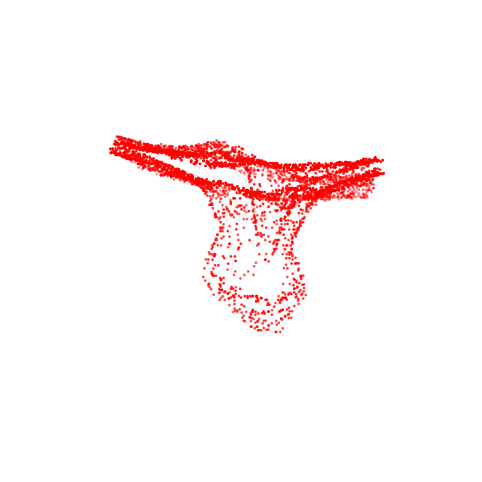

In [35]:
Generate3DPointCloudFromRadialScans(bscan_zoomed_reshape, plot = True)

In [36]:
# from mpl_toolkits.mplot3d import Axes3D
# from matplotlib.animation import FuncAnimation, PillowWriter

# # Load point cloud with labels
# point_cloud = np.load('./temp_pointcloud.npy')  # Shape should be (N, 4) [x, y, z, layer_id]

# # Ensure correct shape
# assert point_cloud.shape[1] == 4, f"Expected shape (N, 4), but got {point_cloud.shape}"

# # Extract only RNFL (layer_id == 1)
# rnfl_points = point_cloud[point_cloud[:, 3] == 1]

# # Extract coordinates
# x, y, z = rnfl_points[:, 0], rnfl_points[:, 1], rnfl_points[:, 2]

# # Define RNFL color
# rnfl_color = "#800080"  # Purple

# # Create figure
# fig = plt.figure()
# ax = fig.add_subplot(111, projection='3d')

# # Scatter plot for RNFL
# sc = ax.scatter(x, y, z, c=rnfl_color, s=1)

# def init():
#     ax.set_xlim(np.min(x), np.max(x))
#     ax.set_ylim(np.min(y), np.max(y))
#     ax.set_zlim(np.min(z), np.max(z))
#     return sc,

# def update(frame):
#     ax.view_init(elev=15, azim=frame)
#     return [],

# # Create animation
# ani = FuncAnimation(fig, update, frames=np.arange(0, 360, 5), init_func=init, blit=False)

# # Save animation
# ani.save("rnfl_point_cloud.gif", writer=PillowWriter(fps=5))

# plt.show()

In [37]:
predicted_labels = bscans_segmented.astype(int)

print(np.shape(predicted_labels[30]))
print(bscans_segmented.shape)
unique_classes, counts = np.unique(predicted_labels[30], return_counts=True)
print(dict(zip(unique_classes, counts)))


# Class to contain the ONH geometry calculation function
class ONHGeometryCalculator:
    def __init__(self):
        pass

    def rotateImage(self, mat, theta, center):

      # Convert the input image to uint8 if necessary
      if mat.dtype != np.uint8:
          mat = mat.astype(np.uint8)
      theta_radians = math.radians(theta)

      # Get the size of the image
      width, height = mat.shape[1], mat.shape[0]

      # Convert numpy array to PIL Image
      img = Image.fromarray(mat)

      result_img = Image.new('RGBA',(width, height), (0, 0, 0, 0))
      print(np.shape(result_img))

      # Rotate the image using Pillow
      rotated_img = img.rotate(-theta, resample=Image.BICUBIC, expand=True)

      # Calculate the offset to apply after the rotation
      pivot_x, pivot_y = center
      x_offset = int(pivot_x - (pivot_x * math.cos(theta_radians) - pivot_y * math.sin(theta_radians)))
      y_offset = int(pivot_y - (pivot_x * math.sin(theta_radians) + pivot_y * math.cos(theta_radians)))

      # Paste the rotated image onto the result image at the adjusted position
      result_img.paste(rotated_img, (x_offset, y_offset), rotated_img)

      # Convert the result back to a numpy array
      result_np = np.array(rotated_img)

      return result_np


    def CalculateONHGeometry(self, mat, OutputFlag=False):
        """
        This function takes label files with layers marked from 1 to 9, not 0 to 8
        """
        ### RPE layer detection, calculates the number of pixels belonging to the RPE layer
        ### along the col direction of the image
        VH_id = 0
        RNFL_id = 1
        GCC_id = 2
        Other_id = 3
        RPE_id = 4
        Corroid_id = 5
        Sclera_id = 6
        LC_id = 7
#        Noise_id = 9
        RPE_layer=[]
        for i in range(0,np.shape(mat)[1]):
            pixel_count = 0
            for j in range(np.shape(mat)[0]):
                if mat[j,i] == RPE_id: ### RPE layer ID
                    pixel_count = pixel_count +1
            RPE_layer.append(pixel_count)

        #print("RPE Layer Detected:", RPE_layer)

        ### BM calculation ==============================================================
        BM_found = False
        BM_start = -1
        BM_end = -1
        minpixel = 60
        tolpixel = 6
        loopcount = 0
        #while BM_found != True:
        while not BM_found and loopcount <= 4:
            minp = int(minpixel*(1-loopcount*0.2))
            tolp = int(tolpixel*(1-loopcount*0.2))
            BM_start = -1
            BM_end = -1
            for i in range(50,len(RPE_layer)-50):
                if RPE_layer[i]==0:
                    if np.sum(RPE_layer[i:(i+minp)]) <= tolp and BM_start == -1:
                        BM_start = i
            for i in range(50,len(RPE_layer)-50):
                j = int(len(RPE_layer)-1-i)
                if RPE_layer[j]==0:
                    if np.sum(RPE_layer[j-minp:j]) <= tolp and BM_end == -1:   ###
                        BM_end = j
            if BM_start != -1 and BM_end != -1:
                BM_found = True

            # if loopcount > 4:
            #     break
            loopcount = loopcount +1

        print("BM Start:", BM_start)
        print("BM End:", BM_end)

        BM_start_r=-1
        BM_start_c=BM_start
        BM_end_r=-1
        BM_end_c=BM_end

        ### this block is for sanity check. if BM can not be found due to bad segmentation
        ### this function returns an array of zeros.
        if BM_start == -1 or BM_end == -1 or BM_start-1 <= -1 or BM_end+1 >=400 or BM_start== BM_end :
            if (OutputFlag==True):
                return np.array([0] * 31),mat # 31 output+mat
            else:
                return np.array([0] * 11),mat # 11 params+mat

        BM_cnt = 1
        while BM_start_r==-1 or BM_end_r==-1:
            for i in range(np.shape(mat)[0]):
                if mat[i,BM_start-BM_cnt] == RPE_id and BM_start_r == -1:
                    BM_start_r = i
                if mat[i,BM_end+BM_cnt] == RPE_id and BM_end_r ==-1:
                    BM_end_r =i
            if BM_cnt > 15:
                break
            BM_cnt +=1

        if BM_start_r==-1 and BM_end_r !=-1:
            BM_start_r = BM_end_r
        elif BM_start_r !=-1 and BM_end_r ==-1:
            BM_end_r = BM_start_r
        else:
            BM_end_r = BM_end_r

        ### rotate image to make BM openings horizontal ==========================
        if np.absolute(BM_start_r-BM_end_r)>12:
            vec_a_i = np.absolute(BM_start_r-BM_end_r)
            vec_a_j = np.absolute(BM_start_c-BM_end_c)
            dist_a = np.sqrt(vec_a_i*vec_a_i+vec_a_j*vec_a_j)
            vec_b_i = 0
            vec_b_j = int(dist_a)
            dist_b = np.sqrt(vec_b_j*vec_b_j)
            theta = math.acos((vec_a_i*vec_b_i+vec_a_j*vec_b_j)/(dist_a*dist_b))*(180.0/3.141)
            if BM_start_r > BM_end_r:
                theta = theta*(-1.0)

            mat = self.rotateImage(mat, theta, [BM_start_c,BM_start_r])
    #         mat = ndimage.rotate(mat, theta, reshape=False)
            #mat = np.reshape(mat,(200,400))
            mat = cv2.resize(mat, (400, 200), interpolation=cv2.INTER_NEAREST)


        ### pixel lenght
        ### we are resizing the image from (496, 384) to (200,400). so we need to adjust the
        ### pixel values.
        #image_width = 4.6702 # this is in mm
        #image_height = 1.9205 # this is in mm
        #px_len_r = image_height/200 ##  this is length of a pixel along the row direction, unit mm
        #px_len_c = image_width/400 ##  this is length of a pixel along the col direcetion, unit mm
        px_len_r = 0.01 ##  this is length of a pixel along the row direction, unit mm
        px_len_c = 0.015 ##  this is length of a pixel along the col direcetion, unit mm

        ### ONH cavity area calculation
        VH_Px_cnt = 0
        for i in range(int((BM_start_r+BM_end_r)/2),200):
            for j in range(BM_start_c,BM_end_c):
                if mat[i,j]==VH_id:
                    VH_Px_cnt = VH_Px_cnt +1
        cavity_area =  VH_Px_cnt*px_len_r*px_len_c*1e6 ## area in micron^2 unit

        ### MRW calculation
        BM_center_c = int((BM_start_c+BM_end_c)/2)
        BM_center_r = int((BM_start_r+BM_end_r)/2)

        MRW_v_start=[]
        MRW_start_rc_vec=[]
        for i in range(BM_start_c,BM_center_c):
            for j in range(np.shape(mat)[0]):
                if mat[j,i]==RNFL_id:
                    cup_r=j
                    cup_c=i
                    dist = np.sqrt(((BM_start_r-cup_r)*px_len_r*1000)**2+((BM_start_c-cup_c)*px_len_c*1000)**2)    #.......
                    MRW_v_start.append(dist)
                    MRW_start_rc_vec.append((cup_r,cup_c))
                    break

        MRW_v_start = np.array(MRW_v_start)
        MRW_start_rc_vec = np.array(MRW_start_rc_vec)
        MRW_start = np.min(MRW_v_start) if len(MRW_v_start) > 0 else 0 ## this is thickness in the unit of micron
        MRW_start_rc = MRW_start_rc_vec[np.argmin(MRW_v_start),:] if len(MRW_v_start) > 0 else (0,0)
        MRW_start_rc = np.array(MRW_start_rc)

        MRW_v_end =[]
        MRW_end_rc_vec=[]
        for i in range(BM_center_c,BM_end_c):
            for j in range(np.shape(mat)[0]):
                if mat[j,i]==RNFL_id:
                    cup_r=j
                    cup_c=i
                    dist = np.sqrt(((BM_end_r-cup_r)*px_len_r*1000)**2+((BM_end_c-cup_c)*px_len_c*1000)**2)
                    MRW_v_end.append(dist)
                    MRW_end_rc_vec.append((cup_r,cup_c))
                    break
        MRW_end = np.min(MRW_v_end) if len(MRW_v_end) > 0 else 0 ## this is thickness in the unit of micron
        MRW_end_rc = MRW_end_rc_vec[np.argmin(MRW_v_end)] if len(MRW_v_end) > 0 else (0,0)
        MRW_end_rc = np.array(MRW_end_rc)

        ### cup calculation
        px_lift_for_cup = 10 #0.130/px_len_r ### 140 micron lift from disc location to get cup location

        cup_found = False
        disc_center_r = -1
        minpx = 60
        loopcount = 0
        px_lift_cnt =0
        cup_start = -1
        cup_end = -1
        while cup_found != True:
            disc_center_r = int(BM_center_r - px_lift_for_cup)
            disc_vector = mat[disc_center_r,BM_start_c:BM_end_c]
            minp = int(minpx*(1-px_lift_cnt*0.2))
            cup_start = -1
            cup_end = -1
            for i in range(len(disc_vector)):
                if disc_vector[i]==VH_id:
                    if np.sum(disc_vector[i:(i+minp)]) <= minp and (i+minp) < len(disc_vector) and  cup_start == -1:
                        cup_start = i
            for i in range(len(disc_vector)):
                j = int(len(disc_vector)-1-i)
                if disc_vector[j]==VH_id:
                    if np.sum(disc_vector[j-minp:j]) <= minp and (j-minp) >0  and cup_end == -1:   ###
                        cup_end = j
            if cup_start != -1 and cup_end != -1:
                cup_found = True

            if px_lift_cnt > 3:
                px_lift_for_cup = px_lift_for_cup +3
                px_lift_cnt =-1

            if loopcount > 15:
                break
            loopcount = loopcount +1
            px_lift_cnt = px_lift_cnt+1
        cup_start_c = cup_start+BM_start_c
        cup_start_r = disc_center_r
        cup_end_c = cup_end+BM_start_c
    #     print(cup_found,cup_start_c,cup_end_c)

        ### ONH parameter calculation
        disc_size = np.absolute(BM_start_c-BM_end_c) *px_len_c*1000 ## unit: micron
        cup_size = np.absolute(cup_start_c-cup_end_c)*px_len_c*1000 ## unit: micron
        if cup_size > 1.1*disc_size or cup_size == 0 or cup_start > cup_end:
            cup_size = 10
            cup_start_c =-1
            cup_end_c =-1

        CDR = cup_size/disc_size
        start_RT = np.absolute(BM_start_c-cup_start_c) if  cup_start_c !=-1 else int(np.absolute(BM_start_c-BM_end_c)/2)    #*px_len_c*1000 ## unit: micron
        end_RT = np.absolute(cup_end_c - BM_end_c) if  cup_end_c !=-1 else int(np.absolute(BM_start_c-BM_end_c)/2)       #*px_len_c*1000 ## unit: micron
        start_RT = start_RT*px_len_c*1000 ## unit: micron
        end_RT = end_RT*px_len_c*1000 ## unit: micron

        ### RNFL, Other and Corroid layer thickness calculation===============
        px_shift_RNFL = 150 #int(1.73/px_len_c) ## number of pixels from the center to measure RNFL thickness
        RNFL_start_c = (BM_center_c - px_shift_RNFL) if (BM_center_c - px_shift_RNFL) > 0 else 0
        RNFL_end_c = (BM_center_c + px_shift_RNFL) if (BM_center_c + px_shift_RNFL) < 400 else 399
        if RNFL_start_c > BM_start_c:
            RNFL_start_c = BM_start_c - 5 if (BM_start_c - 5) >0 else BM_start_c
        if RNFL_end_c < BM_end_c:
            RNFL_end_c = BM_end_c +5 if (BM_end_c +5) < 400 else BM_end_c

        px_start_cnt_RNFL=0
        px_end_cnt_RNFL =0
        px_start_cnt_GCC=0
        px_end_cnt_GCC =0
        px_start_cnt_other =0
        px_end_cnt_other =0
        px_start_cnt_Corroid =0
        px_end_cnt_Corroid =0
        for l in range(np.shape(mat)[0]):
            if mat[l,RNFL_start_c] ==RNFL_id: # id RNFL layer
                px_start_cnt_RNFL = px_start_cnt_RNFL+1
            if mat[l,RNFL_end_c] ==RNFL_id: # id RNFL layer
                px_end_cnt_RNFL = px_end_cnt_RNFL+1

            if mat[l,RNFL_start_c] ==GCC_id: # id GCC layer
                px_start_cnt_GCC = px_start_cnt_GCC+1
            if mat[l,RNFL_end_c] ==GCC_id: # id GCC layer
                px_end_cnt_GCC = px_end_cnt_GCC+1

            if mat[l,RNFL_start_c] ==Other_id: # id Other layer
                px_start_cnt_other = px_start_cnt_other+1
            if mat[l,RNFL_end_c] ==Other_id: # id Other layer
                px_end_cnt_other = px_end_cnt_other+1

            if mat[l,RNFL_start_c] ==Corroid_id: # id Corroid layer
                px_start_cnt_Corroid = px_start_cnt_Corroid+1
            if mat[l,RNFL_end_c] ==Corroid_id: # id Corroid layer
                px_end_cnt_Corroid = px_end_cnt_Corroid+1

        RNFL_start = px_start_cnt_RNFL* px_len_r *1000 ### thickness unit: micron
        RNFL_end = px_end_cnt_RNFL * px_len_r *1000 ### thickness unit: micron
        GCC_start = px_start_cnt_GCC* px_len_r *1000 ### thickness unit: micron
        GCC_end = px_end_cnt_GCC * px_len_r *1000 ### thickness unit: micron
        Other_start = px_start_cnt_other* px_len_r *1000 ### thickness unit: micron
        Other_end = px_end_cnt_other* px_len_r *1000 ### thickness unit: micron
        Corroid_start = px_start_cnt_Corroid* px_len_r *1000 ### thickness unit: micron
        Corroid_end = px_end_cnt_Corroid* px_len_r *1000 ### thickness unit: micron

        MRW = MRW_start if MRW_start < MRW_end else MRW_end ### thickness unit: micron
        RT = start_RT+end_RT ### thickness unit: micron
        RNFL_thick = (RNFL_start+RNFL_end )/2 ### thickness unit: micron
        GCC_thick = (GCC_start+GCC_end )/2 ### thickness unit: micron
        Other_thick = (Other_start+Other_end)/2 ### thickness unit: micron
        Corroid_thick = (Corroid_start+Corroid_end)/2 ### thickness unit: micron

        ### prelamina and LC combined thickness calculation
        px_cnt_PreLam_LC =0
        for l in range(np.shape(mat)[0]):
            if mat[l,BM_center_c] ==RNFL_id or mat[l,BM_center_c] ==LC_id: # id RNFL layer and id LC
                px_cnt_PreLam_LC = px_cnt_PreLam_LC+1
        # Look ±3 columns from center to be tolerant of noisy predictions
        # for offset in range(-3, 4):  # columns from BM_center_c -3 to +3
        #     c = BM_center_c + offset
        #     if c < 0 or c >= mat.shape[1]:
        #         continue
        #     for l in range(mat.shape[0]):
        #         if mat[l, c] == RNFL_id or mat[l, c] == LC_id:
        #             px_cnt_PreLam_LC += 1

        PreLam_LC_thick = px_cnt_PreLam_LC* px_len_r *1000 ### thickness unit: micron

        if (OutputFlag==True):
            return np.array([BM_start_r,BM_start_c,BM_end_r,BM_end_c, \
                   cup_start_r,cup_start_c,cup_start_r, cup_end_c, \
                   MRW_start,MRW_end, disc_size,cup_size,CDR,start_RT,end_RT,\
                   RNFL_start_c, RNFL_end_c, RNFL_start,RNFL_end,cavity_area,\
                   MRW_start_rc[0],MRW_start_rc[1], MRW_end_rc[0],MRW_end_rc[1],\
                   GCC_start,GCC_end,Other_start,Other_end,Corroid_start,Corroid_end,\
                   PreLam_LC_thick]),\
                   mat ### 31 params+mat
        else:
            return np.array([MRW, disc_size, cup_size, CDR, RT,cavity_area, RNFL_thick, GCC_thick ,Other_thick,Corroid_thick,PreLam_LC_thick]),mat  ### 11 parameters+mat

# Initialize the geometry calculator
calculator = ONHGeometryCalculator()


all_onh_params = []
for i in range(30, 31):
    mat = predicted_labels[i]
    onh_params, processed_mat = calculator.CalculateONHGeometry(mat, OutputFlag=False)
    all_onh_params.append(onh_params)

print(f"Total number of ONH parameter sets: {len(all_onh_params)}")
print(f"Example ONH parameters for scan 0: {all_onh_params}")

(200, 400)
(73, 200, 400)
{np.int64(0): np.int64(52531), np.int64(1): np.int64(12285), np.int64(2): np.int64(1115), np.int64(3): np.int64(3477), np.int64(4): np.int64(783), np.int64(5): np.int64(3720), np.int64(6): np.int64(5454), np.int64(7): np.int64(635)}
BM Start: 134
BM End: 241
Total number of ONH parameter sets: 1
Example ONH parameters for scan 0: [array([3.2035137e+02, 1.6050000e+03, 1.0000000e+01, 6.2305296e-03,
       1.5900000e+03, 1.2441000e+06, 6.5000000e+01, 5.0000000e+01,
       1.3500000e+02, 1.2500000e+02, 9.2000000e+02])]


In [38]:
plt.ioff()  # turn off interactive plotting

onh_areas = []
all_onh_params = []

for i in range(predicted_labels.shape[0]):
    mat = predicted_labels[i]
    onh_params, _ = calculator.CalculateONHGeometry(mat, OutputFlag=False)
    
    # Extract the ONH cavity area (6th parameter in your 11-param output)
    cavity_area = onh_params[5]
    onh_areas.append(cavity_area)
    all_onh_params.append(onh_params)

plt.close('all')  # close any residual figures
    



BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: 319
BM End: 349
BM Start: 349
BM End: -1
BM Start: 303
BM End: 323
BM Start: 306
BM End: 329
(200, 400, 4)
BM Start: 294
BM End: 329
BM Start: 304
BM End: 315
BM Start: -1
BM End: -1
BM Start: 286
BM End: 349
BM Start: 300
BM End: 327
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: -1
BM End: -1
BM Start: 276
BM End: 298
BM Start: 181
BM End: 239
BM Start: 175
BM End: 208
BM Start: 171
BM End: 226
BM Start: 155
BM End: 250
BM Start: 149
BM End: 239
BM Start: 149
BM End: 240
BM Start: 149
BM End: 243
BM Start: 139
BM End: 233
BM Start: 135
BM End: 243
BM Start: 134
BM End: 241
BM Start: 133
BM End: 238
BM Start: 130
BM End: 234
BM Start: 130
BM End: 236
BM Start: 128
BM End: 233
BM Start: 127
BM End: 236
BM Start: 127
BM End: 231
BM Start: 128
BM End: 236
BM Start: 127
BM End: 2

B-scan with largest ONH cavity: Index 31
Max cavity area: 1356750.00 µm²
BM Start: 133
BM End: 238
Selected B-scan index: 31
ONH parameters: [3.00374766e+02 1.57500000e+03 1.00000000e+01 6.34920635e-03
 1.56000000e+03 1.35675000e+06 5.50000000e+01 5.50000000e+01
 1.35000000e+02 1.25000000e+02 7.70000000e+02]


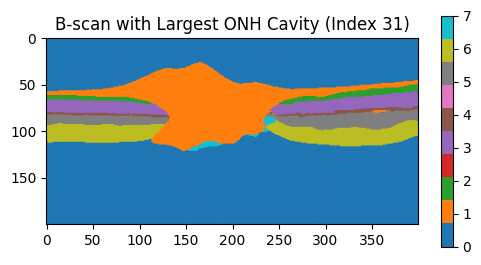

In [40]:
max_area_idx = np.argmax(onh_areas)
print(f"B-scan with largest ONH cavity: Index {max_area_idx}")
print(f"Max cavity area: {onh_areas[max_area_idx]:.2f} µm²")

best_scan = predicted_labels[max_area_idx]
onh_params, processed_mat = calculator.CalculateONHGeometry(best_scan, OutputFlag=False)

print(f"Selected B-scan index: {max_area_idx}")
print("ONH parameters:", onh_params)

plt.figure(figsize=(6, 3))
plt.imshow(best_scan, cmap='tab10')
plt.title(f"B-scan with Largest ONH Cavity (Index {max_area_idx})")
plt.colorbar()
plt.show()